# Pemodelan dan Simulasi — Prakiraan Kunjungan Wisatawan Mancanegara ke Indonesia

**Metode:** (1) Exponential Smoothing (SES, Holt, Holt-Winters) dan (2) Regresi Linear
**Data:** Jumlah Kunjungan Wisman per bulan menurut Pintu Masuk, 2023 – 2026 (BPS / Kemenparekraf)

Notebook ini **interaktif** (input pengguna ada di **bagian paling bawah**): pilih pintu masuk, metode, parameter, jumlah data uji, dan horizon prakiraan, lalu klik **Jalankan**.
Anda juga bisa memasukkan **data sendiri** (deret bulanan) pada kolom input manual.

**Cara pakai**
1. Jalankan sel dari atas ke bawah (*Runtime → Run all* di Colab).
2. Jika file CSV belum ada di folder kerja, Colab akan meminta Anda mengunggah 4 file CSV (2023–2026).
3. Untuk mencoba data/parameter sendiri, atur widget pada bagian *Simulasi Interaktif* (**sel paling bawah**), lalu tekan **Jalankan**.

In [1]:
# 1. Setup
import io, csv, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from IPython.display import display
warnings.filterwarnings('ignore')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})
pd.options.display.float_format = '{:,.0f}'.format

## 1. Memuat Data

In [2]:
TAHUN_AWAL = 2023   # data sebelum tahun ini tidak dipakai
BULAN = ['Januari','Februari','Maret','April','Mei','Juni','Juli','Agustus','September','Oktober','November','Desember']

def parse_csv_text(teks):
    """Ubah satu file CSV BPS (satu tahun) menjadi tabel panjang: pintu, tahun, bulan, jumlah."""
    baris = list(csv.reader(io.StringIO(teks)))
    tahun = next(int(r[1]) for r in baris if len(r) > 1 and r[1].strip().isdigit() and len(r[1].strip()) == 4)
    mulai = next(i for i, r in enumerate(baris) if len(r) > 1 and r[1].strip() == 'Januari') + 1
    out = []
    for r in baris[mulai:]:
        if not r or not r[0].strip():
            continue
        for i in range(12):
            v = r[1 + i].strip().replace(',', '')
            if v in ('-', ''):
                continue            # bulan belum tersedia (mis. Okt–Des 2026)
            out.append((r[0].strip(), tahun, i + 1, float(v)))
    return out

def muat_data():
    jalur = sorted(glob.glob('*Wisatawan_Mancanegara*.csv') + glob.glob('/content/*Wisatawan_Mancanegara*.csv'))
    jalur = sorted(set(jalur))
    if jalur:
        sumber = [open(p, encoding='utf-8-sig').read() for p in jalur]
    else:
        try:
            from google.colab import files            # khusus Google Colab
            print('Unggah keempat file CSV (2023–2026):')
            up = files.upload()
            sumber = [b.decode('utf-8-sig') for b in up.values()]
        except ImportError:
            raise FileNotFoundError('Letakkan file CSV di folder yang sama dengan notebook ini.')
    baris = [r for s in sumber for r in parse_csv_text(s)]
    df = pd.DataFrame(baris, columns=['pintu', 'tahun', 'bulan', 'jumlah'])
    df = df[df.tahun >= TAHUN_AWAL]
    df['tanggal'] = pd.to_datetime(dict(year=df.tahun, month=df.bulan, day=1))
    return df.sort_values(['pintu', 'tanggal']).reset_index(drop=True)

DF = muat_data()
print(f'{len(DF):,} baris | {DF.pintu.nunique()} pintu masuk | {DF.tanggal.min():%b %Y} – {DF.tanggal.max():%b %Y}')
tahunan = DF[DF.pintu == 'Total'].groupby('tahun').jumlah.agg(['sum', 'count']).rename(columns={'sum': 'Total kunjungan', 'count': 'Jumlah bulan'})
tahunan

Unggah keempat file CSV (2023–2026):


Saving Jumlah Kunjungan Wisatawan Mancanegara per bulan ke Indonesia Menurut Pintu Masuk, 2008 - sekarang, 2023.csv to Jumlah Kunjungan Wisatawan Mancanegara per bulan ke Indonesia Menurut Pintu Masuk, 2008 - sekarang, 2023.csv
Saving Jumlah Kunjungan Wisatawan Mancanegara per bulan ke Indonesia Menurut Pintu Masuk, 2008 - sekarang, 2024.csv to Jumlah Kunjungan Wisatawan Mancanegara per bulan ke Indonesia Menurut Pintu Masuk, 2008 - sekarang, 2024.csv
Saving Jumlah Kunjungan Wisatawan Mancanegara per bulan ke Indonesia Menurut Pintu Masuk, 2008 - sekarang, 2025.csv to Jumlah Kunjungan Wisatawan Mancanegara per bulan ke Indonesia Menurut Pintu Masuk, 2008 - sekarang, 2025.csv
Saving Jumlah Kunjungan Wisatawan Mancanegara per bulan ke Indonesia Menurut Pintu Masuk, 2008 - sekarang, 2026.csv to Jumlah Kunjungan Wisatawan Mancanegara per bulan ke Indonesia Menurut Pintu Masuk, 2008 - sekarang, 2026.csv
1,540 baris | 35 pintu masuk | Jan 2023 – Sep 2026


,Total kunjungan,Jumlah bulan
tahun,,
2023,"11,677,825",12
2024,"13,886,678",12
2025,"15,386,646",12
2026,"12,005,400",9


## 2. Fungsi Model

**Exponential Smoothing**
- **SES**: $\ell_t = \alpha y_t + (1-\alpha)\ell_{t-1}$, prakiraan $\hat y_{t+h}=\ell_t$
- **Holt** (tren): $\ell_t=\alpha y_t+(1-\alpha)(\ell_{t-1}+b_{t-1})$, $b_t=\beta(\ell_t-\ell_{t-1})+(1-\beta)b_{t-1}$, $\hat y_{t+h}=\ell_t+h\,b_t$
- **Holt-Winters** (tren + musiman, periode $m=12$):
  multiplikatif $\hat y_{t+h}=(\ell_t+h\,b_t)\,s_{t+h-m}$; aditif $\hat y_{t+h}=\ell_t+h\,b_t+s_{t+h-m}$

**Regresi Linear** (tren waktu): $\hat y = a + b\,t$ dengan $b=\dfrac{\sum (t-\bar t)(y-\bar y)}{\sum (t-\bar t)^2}$, $a=\bar y-b\bar t$

In [3]:
def ses(y, a, h=0):
    l = y[0]; fit = [y[0]]
    for t in range(1, len(y)):
        fit.append(l); l = a * y[t] + (1 - a) * l
    return np.array(fit), np.repeat(l, h)

def holt(y, a, b, h=0):
    l = y[0]; T = y[1] - y[0]; fit = [y[0]]
    for t in range(1, len(y)):
        fit.append(l + T)
        ln = a * y[t] + (1 - a) * (l + T)
        T = b * (ln - l) + (1 - b) * T; l = ln
    return np.array(fit), np.array([l + (k + 1) * T for k in range(h)])

def holt_winters(y, a, b, g, m=12, h=0, mode='mul'):
    y = np.asarray(y, float); n = len(y)
    l = y[:m].mean(); T = (y[m:2*m].mean() - y[:m].mean()) / m
    s = list(y[:m] / l) if mode == 'mul' else list(y[:m] - l)
    fit = list(y[:m])
    for t in range(m, n):
        st = s[t - m]
        fit.append((l + T) * st if mode == 'mul' else l + T + st)
        ln = a * (y[t] / st if mode == 'mul' else y[t] - st) + (1 - a) * (l + T)
        Tn = b * (ln - l) + (1 - b) * T
        sn = g * (y[t] / ln if mode == 'mul' else y[t] - ln) + (1 - g) * st
        s.append(sn); l, T = ln, Tn
    fc = []
    for k in range(1, h + 1):
        st = s[n - m + ((k - 1) % m)]
        fc.append((l + k * T) * st if mode == 'mul' else l + k * T + st)
    return np.array(fit), np.array(fc)

def regresi_linear(x, y):
    x = np.asarray(x, float); y = np.asarray(y, float)
    b = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()
    a = y.mean() - b * x.mean()
    r2 = 1 - ((y - (a + b * x)) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    r = np.corrcoef(x, y)[0, 1]
    return a, b, r2, r

def mape(y, f): y, f = np.asarray(y), np.asarray(f); return np.mean(np.abs((y - f) / y)) * 100
def rmse(y, f): y, f = np.asarray(y), np.asarray(f); return np.sqrt(np.mean((y - f) ** 2))
def mae(y, f):  y, f = np.asarray(y), np.asarray(f); return np.mean(np.abs(y - f))

# pencarian parameter (meminimalkan SSE data latih)
def cari_ses(y):
    return min(np.arange(0.01, 1, 0.01), key=lambda a: np.sum((y[1:] - ses(y, a)[0][1:]) ** 2))

def cari_holt(y):
    grid = [(a, b) for a in np.arange(0.05, 1, 0.05) for b in np.arange(0.05, 1, 0.05)]
    return min(grid, key=lambda p: np.sum((y[2:] - holt(y, *p)[0][2:]) ** 2))

def cari_hw(y, mode, m=12):
    terbaik = None
    for x0 in [(0.3, 0.1, 0.3), (0.6, 0.05, 0.2), (0.2, 0.2, 0.5)]:
        r = minimize(lambda p: np.sum((y[m:] - holt_winters(y, *p, m=m, mode=mode)[0][m:]) ** 2),
                     x0, bounds=[(0.01, 0.99)] * 3, method='L-BFGS-B')
        if terbaik is None or r.fun < terbaik.fun:
            terbaik = r
    return tuple(terbaik.x)

## 3. Mesin Simulasi
Fungsi `jalankan_model` melatih satu model pada data latih, menguji pada *N* bulan terakhir (data uji), lalu melatih ulang pada seluruh data untuk memprakirakan *h* bulan ke depan.

In [4]:
METODE = ['SES', 'Holt', 'Holt-Winters Multiplikatif', 'Holt-Winters Aditif', 'Regresi Linear']

def jalankan_model(y, metode, n_uji, h, auto=True, a=0.5, b=0.1, g=0.3, m=12):
    y = np.asarray(y, float); n = len(y)
    ytr = y[:n - n_uji] if n_uji > 0 else y
    if metode.startswith('Holt-Winters') and len(ytr) < 2 * m:
        raise ValueError(f'Holt-Winters membutuhkan minimal {2*m} data latih (saat ini {len(ytr)}). Kurangi data uji atau mulai dari tahun lebih awal.')
    if len(ytr) < 4:
        raise ValueError('Data latih terlalu sedikit.')

    def fit_predict(seri, hh):
        """Latih pada 'seri', kembalikan (fitted, prakiraan hh langkah, parameter, info)."""
        if metode == 'SES':
            p = (cari_ses(seri),) if auto else (a,)
            f, fc = ses(seri, *p, h=hh); return f, fc, {'alpha': p[0]}, {}
        if metode == 'Holt':
            p = cari_holt(seri) if auto else (a, b)
            f, fc = holt(seri, *p, h=hh); return f, fc, {'alpha': p[0], 'beta': p[1]}, {}
        if metode.startswith('Holt-Winters'):
            mode = 'mul' if 'Multi' in metode else 'add'
            p = cari_hw(seri, mode, m) if auto else (a, b, g)
            f, fc = holt_winters(seri, *p, m=m, h=hh, mode=mode)
            return f, fc, {'alpha': p[0], 'beta': p[1], 'gamma': p[2]}, {}
        # Regresi linear
        x = np.arange(1, len(seri) + 1)
        A, B, r2, r = regresi_linear(x, seri)
        return A + B * x, A + B * (len(seri) + 1 + np.arange(hh)), {}, {'a': A, 'b': B, 'R2': r2, 'r': r}

    hasil = {'metode': metode, 'n_uji': n_uji}
    fit_tr, fc_uji, par, info = fit_predict(ytr, n_uji)
    hasil['param'], hasil['info'] = par, info
    hasil['fitted'] = fit_tr
    if n_uji > 0:
        yuji = y[n - n_uji:]
        hasil['uji'] = {'aktual': yuji, 'prakiraan': fc_uji,
                        'MAPE (%)': mape(yuji, fc_uji), 'RMSE': rmse(yuji, fc_uji), 'MAE': mae(yuji, fc_uji)}
    _, fc_depan, par_all, info_all = fit_predict(y, h)
    hasil['depan'] = fc_depan; hasil['param_all'] = par_all; hasil['info_all'] = info_all
    return hasil

def ambil_seri(sumber, pintu, tahun_mulai, teks_manual, bulan_awal):
    if sumber == 'Input manual':
        nilai = [float(v) for v in teks_manual.replace('\n', ',').replace(';', ',').split(',') if v.strip()]
        tgl = pd.date_range(pd.Timestamp(bulan_awal + '-01'), periods=len(nilai), freq='MS')
        return pd.Series(nilai, index=tgl, name='Data manual')
    d = DF[(DF.pintu == pintu) & (DF.tahun >= tahun_mulai)].sort_values('tanggal')
    return pd.Series(d.jumlah.values, index=pd.DatetimeIndex(d.tanggal), name=pintu)

## 4. Visualisasi dan Laporan Hasil

Fungsi grafik di bawah menghasilkan gambar: warna, judul, sumbu, dan urutan


In [5]:
import matplotlib.dates as mdates

BLN = ['Jan','Feb','Mar','Apr','Mei','Jun','Jul','Agu','Sep','Okt','Nov','Des']
NAVY, ABU = '#0B3C5D', '#8A94A3'
WARNA = {'Holt-Winters Multiplikatif': '#E4572E', 'Regresi Linear': '#F2A541', 'SES': '#1D8A99',
         'Holt': '#7A5195', 'Holt-Winters Aditif': '#6BAA75'}
SINGKAT = {'Holt-Winters Multiplikatif': 'HW Multiplikatif', 'Holt-Winters Aditif': 'HW Aditif'}
NAMA_MAPE = {'Holt-Winters Multiplikatif': 'Holt-Winters Mult.', 'Holt-Winters Aditif': 'Holt-Winters Adt.'}

def _bln(ts): return f'{BLN[ts.month - 1]} {ts.year}'
def _rentang(a, b):
    return f'{BLN[a.month - 1]}–{BLN[b.month - 1]} {b.year}' if a.year == b.year else f'{_bln(a)} – {_bln(b)}'

def _rapikan(ax, judul, ylabel='Kunjungan (juta)', waktu=None):
    ax.set_title(judul, loc='left', fontweight='bold')
    ax.set_ylabel(ylabel); ax.grid(axis='y', alpha=.25); ax.set_axisbelow(True)
    if waktu == 'semester':
        ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    elif waktu == 'tahun':
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

def grafik_deret(seri):
    """deret waktu kunjungan bulanan."""
    nama = 'Kunjungan wisman bulanan ke Indonesia' if seri.name == 'Total' else f'Kunjungan wisman bulanan: {seri.name}'
    fig, ax = plt.subplots(figsize=(10, 4.6))
    ax.plot(seri.index, seri.values / 1e6, color=NAVY, lw=2.2)
    _rapikan(ax, f'{nama}, {_rentang(seri.index[0], seri.index[-1])}', waktu='semester')
    plt.tight_layout(); plt.show()

def grafik_musiman(seri):
    """indeks musiman rata-rata (nilai bulan ÷ rata-rata tahun, dirata-ratakan antartahun lengkap)."""
    d = pd.DataFrame({'th': seri.index.year, 'bl': seri.index.month, 'y': seri.values})
    d = d[d.groupby('th').y.transform('count') == 12]
    if d.empty:
        print('Indeks musiman tidak ditampilkan: tidak ada tahun kalender yang lengkap (12 bulan).'); return
    d['idx'] = d.y / d.groupby('th').y.transform('mean')
    idx = d.groupby('bl').idx.mean()
    th = sorted(d.th.unique())
    judul = f'Pola musiman rata-rata {th[0]}–{th[-1]}' if len(th) > 1 else f'Pola musiman {th[0]}'
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.bar(BLN, idx.values, color=[WARNA['Holt-Winters Multiplikatif'] if v > 1.05 else NAVY for v in idx.values])
    ax.axhline(1, color=ABU, lw=1.3)
    _rapikan(ax, judul, ylabel='Indeks musiman')
    plt.tight_layout(); plt.show()

def grafik_uji(seri, hasil_list):
    """prakiraan model pada data uji."""
    n = len(seri); idx = seri.index; nu = hasil_list[0]['n_uji']
    fig, ax = plt.subplots(figsize=(10, 4.6))
    ax.plot(idx[:n - nu], seri.values[:n - nu] / 1e6, color=ABU, lw=2, label=f'Data latih ({idx[0].year}–{idx[n - nu - 1].year})')
    th0, th1 = idx[n - nu].year, idx[-1].year
    ax.plot(idx[n - nu:], seri.values[n - nu:] / 1e6, color=NAVY, lw=3.4, marker='o', ms=6,
            label=f'Aktual {th0}' if th0 == th1 else f'Aktual {th0}–{th1}')
    for hs in hasil_list:
        ax.plot(idx[n - nu:], hs['uji']['prakiraan'] / 1e6, ls='--', lw=2.2, color=WARNA[hs['metode']],
                label=SINGKAT.get(hs['metode'], hs['metode']))
    _rapikan(ax, f'Uji model pada data {_rentang(idx[n - nu], idx[-1])}', waktu='semester')
    ax.legend(frameon=False, fontsize=9, ncol=2, loc='upper left')
    plt.tight_layout(); plt.show()

def grafik_regresi(seri, n_uji, hs):
    """garis regresi linear pada data latih."""
    n = len(seri); y = seri.values[:n - n_uji]; t = np.arange(1, len(y) + 1); i = hs['info']
    fig, ax = plt.subplots(figsize=(10, 4.6))
    ax.scatter(t, y / 1e6, color=NAVY, s=32, zorder=3)
    ax.plot(t, (i['a'] + i['b'] * t) / 1e6, color=WARNA['Holt-Winters Multiplikatif'], lw=3)
    _rapikan(ax, f"Regresi linear tren: ŷ = {i['a']:,.0f} + {i['b']:,.0f}t  (R² = {i['R2']:.3f})")
    ax.set_xlabel(f'Periode (t, 1 = {_bln(seri.index[0])})'); ax.set_xlim(left=-0.5)
    plt.tight_layout(); plt.show()

def grafik_prakiraan(seri, hasil_list, h):
    """prakiraan h bulan ke depan."""
    tgl = pd.date_range(seri.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq='MS')
    fig, ax = plt.subplots(figsize=(10, 4.6))
    ax.plot(seri.index, seri.values / 1e6, color=NAVY, lw=2.2, label='Aktual')
    for hs in hasil_list:
        c = WARNA[hs['metode']]
        if hs['metode'] == 'Regresi Linear':
            ax.plot(tgl, hs['depan'] / 1e6, ls='--', lw=2.2, color=c, label='Regresi Linear')
        else:
            ax.plot(tgl, hs['depan'] / 1e6, lw=2.6, marker='o', ms=4.5, color=c,
                    label=f"Prakiraan {SINGKAT.get(hs['metode'], hs['metode'])}")
    _rapikan(ax, f'Prakiraan {_rentang(tgl[0], tgl[-1])}', waktu='tahun')
    ax.legend(frameon=False, loc='upper left')
    plt.tight_layout(); plt.show()

def grafik_mape(seri, hasil_list):
    """Grafik batang MAPE antarmodel pada data uji (seperti slide hasil presentasi)."""
    rows = sorted([(NAMA_MAPE.get(hs['metode'], hs['metode']), hs['uji']['MAPE (%)']) for hs in hasil_list if hs['n_uji'] > 0],
                  key=lambda r: r[1])
    n = len(seri); nu = hasil_list[0]['n_uji']
    fig, ax = plt.subplots(figsize=(10, 3.6))
    bars = ax.barh([r[0] for r in rows], [r[1] for r in rows], color=NAVY)
    ax.invert_yaxis(); ax.bar_label(bars, fmt='%.2f', padding=4)
    ax.set_xlim(0, max(r[1] for r in rows) * 1.12); ax.grid(axis='x', alpha=.25); ax.set_axisbelow(True)
    ax.set_title(f'MAPE data uji {_rentang(seri.index[n - nu], seri.index[-1])} (%, makin kecil makin baik)', loc='left', fontweight='bold')
    ax.set_xlabel('MAPE (%)')
    plt.tight_layout(); plt.show()

def tabel_akurasi(hasil_list):
    rows = [{'Metode': hs['metode'], 'MAPE (%)': hs['uji']['MAPE (%)'], 'RMSE': hs['uji']['RMSE'], 'MAE': hs['uji']['MAE']}
            for hs in hasil_list if hs['n_uji'] > 0]
    if rows:
        print('Akurasi pada data uji (semakin kecil semakin baik):')
        display(pd.DataFrame(rows).set_index('Metode').sort_values('MAPE (%)')
                .style.format({'MAPE (%)': '{:.2f}', 'RMSE': '{:,.0f}', 'MAE': '{:,.0f}'}))

def info_parameter(hasil_list):
    for hs in hasil_list:
        if hs['param']:
            print(f"Parameter {hs['metode']} (data latih): " + ', '.join(f'{k}={v:.3f}' for k, v in hs['param'].items()))
        if hs['info']:
            i = hs['info']
            print(f"Regresi (data latih): ŷ = {i['a']:,.2f} + {i['b']:,.2f}·t | r = {i['r']:.4f} | R² = {i['R2']:.4f}")

def tabel_prakiraan(seri, hasil_list, h):
    tgl = pd.date_range(seri.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq='MS')
    print(f'\nPrakiraan {h} bulan ke depan:')
    display(pd.DataFrame({hs['metode']: hs['depan'] for hs in hasil_list}, index=[_bln(t) for t in tgl]))

def tampilkan(seri, hasil_list, h):
    """Laporan lengkap (dipakai widget): grafik bergaya laporan + tabel akurasi, parameter, dan prakiraan."""
    grafik_deret(seri); grafik_musiman(seri)
    nu = hasil_list[0]['n_uji']
    if nu > 0:
        grafik_uji(seri, hasil_list)
        if len(hasil_list) > 1: grafik_mape(seri, hasil_list)
    for hs in hasil_list:
        if hs['metode'] == 'Regresi Linear': grafik_regresi(seri, nu, hs)
    grafik_prakiraan(seri, hasil_list, h)
    tabel_akurasi(hasil_list); info_parameter(hasil_list); tabel_prakiraan(seri, hasil_list, h)

## 5. Visualisasi Hasil dan Perbandingan Seluruh Metode (Total Kunjungan, uji Jan–Sep 2026)
Sel berikut menjalankan kelima model pada deret **Total** (2023–2026) tanpa interaksi dan menghasilkan **Gambar 1–5** seperti pada laporan, ditambah grafik MAPE dan tabel akurasi/prakiraan, sebagai acuan hasil laporan.

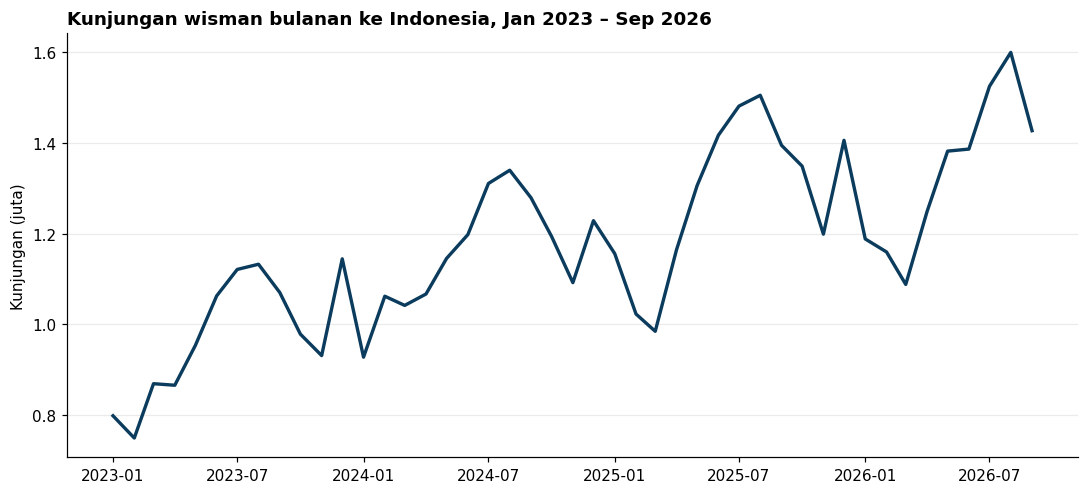

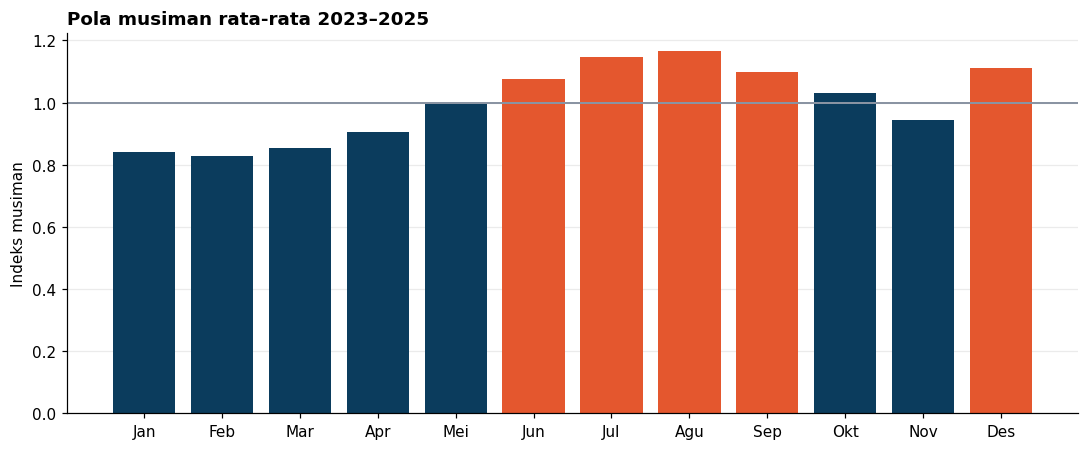

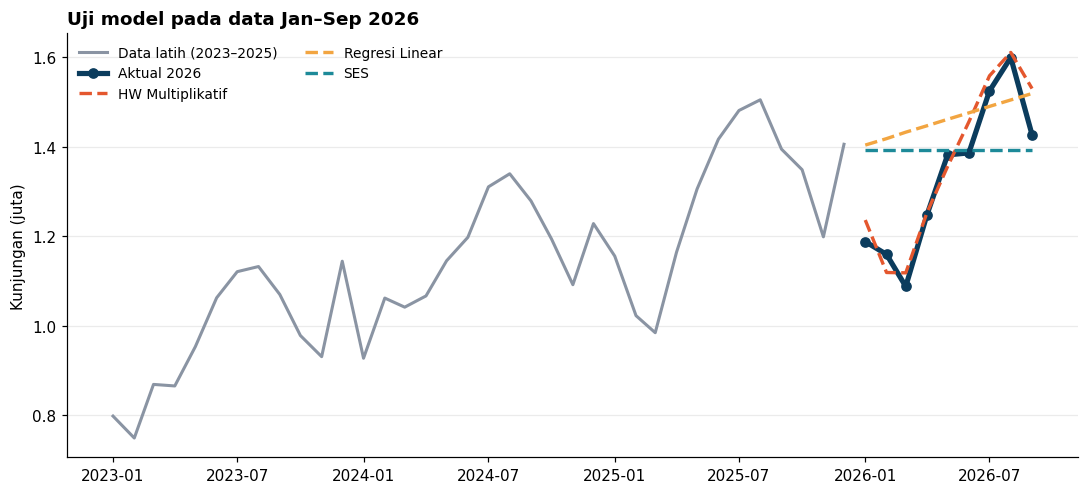

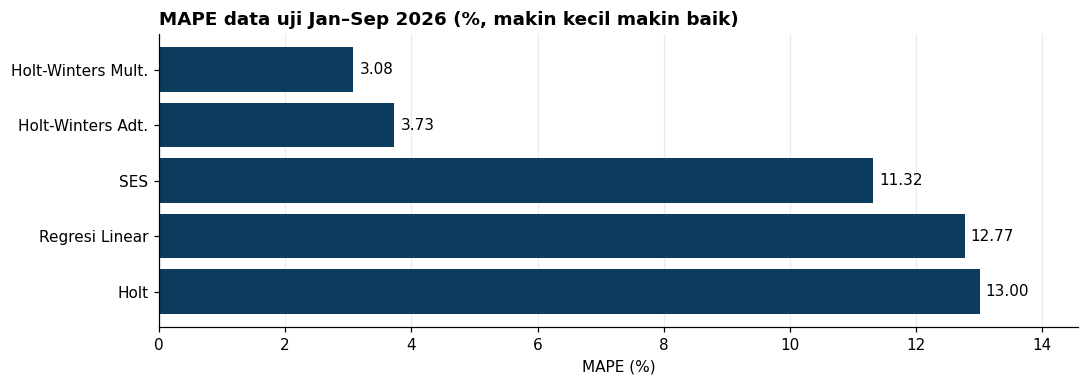

Akurasi pada data uji (semakin kecil semakin baik):


,MAPE (%),RMSE,MAE
Metode,,,
Holt-Winters Multiplikatif,3.08,"49,776","40,800"
Holt-Winters Aditif,3.73,"57,303","47,511"
SES,11.32,"173,397","141,625"
Regresi Linear,12.77,"184,005","156,474"
Holt,13.00,"187,513","159,246"


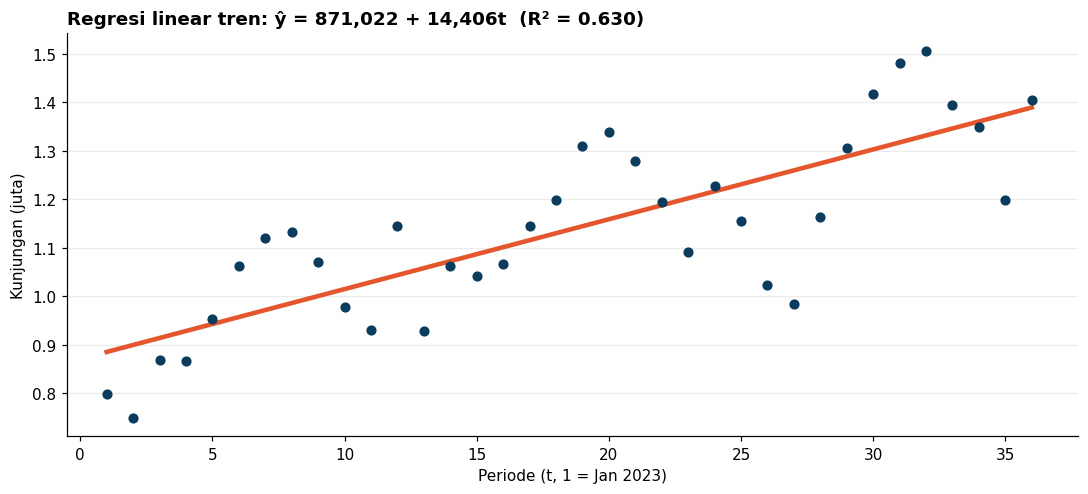

Parameter SES (data latih): alpha=0.930
Parameter Holt (data latih): alpha=0.950, beta=0.100
Parameter Holt-Winters Multiplikatif (data latih): alpha=0.516, beta=0.010, gamma=0.990
Parameter Holt-Winters Aditif (data latih): alpha=0.570, beta=0.010, gamma=0.990
Regresi (data latih): ŷ = 871,021.79 + 14,405.95·t | r = 0.7937 | R² = 0.6300


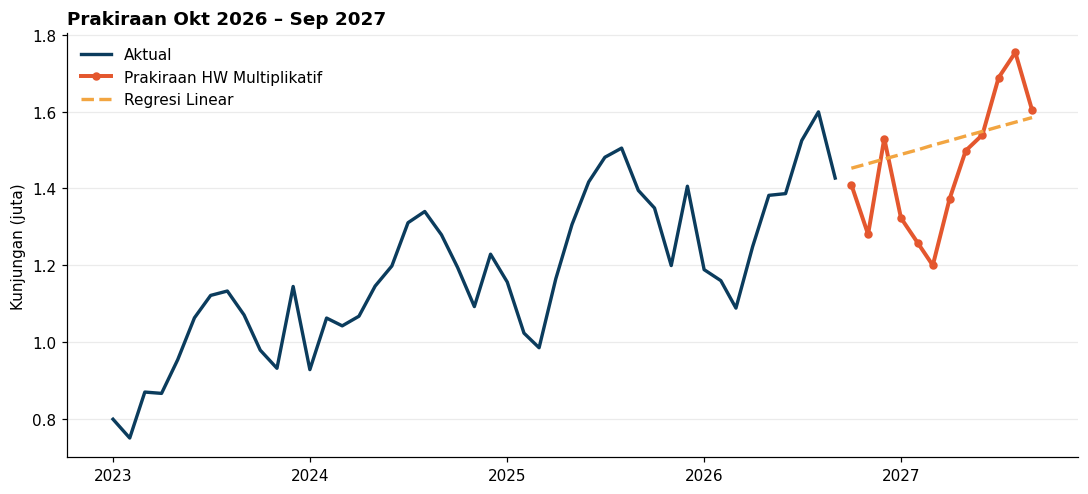


Prakiraan 12 bulan ke depan:


,Holt-Winters Multiplikatif,Regresi Linear
Okt 2026,"1,409,745","1,452,783"
Nov 2026,"1,280,435","1,464,782"
Des 2026,"1,530,227","1,476,781"
Jan 2027,"1,322,949","1,488,780"
Feb 2027,"1,258,251","1,500,778"
Mar 2027,"1,199,537","1,512,777"
Apr 2027,"1,372,244","1,524,776"
Mei 2027,"1,498,422","1,536,775"
Jun 2027,"1,539,940","1,548,773"
Jul 2027,"1,688,824","1,560,772"


In [6]:
seri_total = ambil_seri('Dataset BPS', 'Total', 2023, '', '')
hasil_semua = [jalankan_model(seri_total.values, m, 9, 12) for m in METODE]
H = {hs['metode']: hs for hs in hasil_semua}

#  deret waktu |  pola musiman
grafik_deret(seri_total)
grafik_musiman(seri_total)

#  prakiraan model pada data uji (+ perbandingan MAPE seperti slide presentasi)
grafik_uji(seri_total, [H['Holt-Winters Multiplikatif'], H['Regresi Linear'], H['SES']])
grafik_mape(seri_total, hasil_semua)
tabel_akurasi(hasil_semua)

#  regresi linear pada data latih
grafik_regresi(seri_total, 9, H['Regresi Linear'])
info_parameter(hasil_semua)

#  prakiraan Okt 2026 – Sep 2027
grafik_prakiraan(seri_total, [H['Holt-Winters Multiplikatif'], H['Regresi Linear']], 12)
tabel_prakiraan(seri_total, [H['Holt-Winters Multiplikatif'], H['Regresi Linear']], 12)

## 6. Kesimpulan Singkat
- Deret kunjungan wisman memiliki **tren naik** dan **pola musiman** yang kuat (puncak Juli–Agustus dan Desember; terendah Januari–Maret).
- **Holt-Winters** (tren + musiman) jauh lebih akurat daripada SES, Holt, maupun regresi linear tren karena ketiganya tidak menangkap musiman.
- **Regresi linear** berguna untuk menunjukkan arah dan laju pertumbuhan (kenaikan rata-rata per bulan), tetapi kurang akurat sebagai alat prakiraan bulanan.
- Pada bagian *Simulasi Interaktif* di bawah, coba ganti pintu masuk (mis. *Ngurah Rai*, *Soekarno-Hatta*, *Batam*) atau data manual untuk melihat bagaimana ketepatan model berubah.

## 7. Simulasi Interaktif
Atur widget di bawah, lalu tekan **Jalankan**.
- *Sumber data*: dataset BPS atau **input manual** (isi nilai bulanan dipisah koma, mis. `120,130,125,...`, dan tentukan bulan awal `YYYY-MM`).
- *Data uji*: jumlah bulan terakhir yang disembunyikan untuk menguji akurasi.
- Hilangkan centang *Optimasi otomatis* untuk mengatur α, β, γ secara manual.

In [7]:
try:
    import ipywidgets as w
    from IPython.display import display, clear_output
    ADA_WIDGET = True
except ImportError:
    ADA_WIDGET = False
    from IPython.display import display
    print('ipywidgets tidak tersedia — gunakan sel "Mode teks" di bawah.')

if ADA_WIDGET:
    daftar_pintu = ['Total'] + sorted(p for p in DF.pintu.unique() if p not in ('Total', 'Jumlah (A+B+C)', 'Lainnya'))
    st = {'description_width': '150px'}; lay = w.Layout(width='430px')
    dd_sumber = w.Dropdown(options=['Dataset BPS', 'Input manual'], description='Sumber data', style=st, layout=lay)
    dd_pintu  = w.Dropdown(options=daftar_pintu, value='Total', description='Pintu masuk', style=st, layout=lay)
    dd_mulai  = w.Dropdown(options=[2023, 2024], value=2023, description='Mulai tahun', style=st, layout=lay)
    ta_manual = w.Textarea(placeholder='Contoh: 120,130,125,140,...', description='Data manual', style=st, layout=w.Layout(width='430px', height='60px'))
    tx_awal   = w.Text(value='2023-01', description='Bulan awal (YYYY-MM)', style=st, layout=lay)
    sel_metode = w.SelectMultiple(options=METODE, value=('Holt-Winters Multiplikatif', 'Regresi Linear'), description='Metode', style=st, layout=w.Layout(width='430px', height='110px'))
    sl_uji = w.IntSlider(value=9, min=0, max=18, description='Data uji (bulan)', style=st, layout=lay)
    sl_h   = w.IntSlider(value=12, min=1, max=24, description='Horizon (bulan)', style=st, layout=lay)
    cb_auto = w.Checkbox(value=True, description='Optimasi parameter otomatis', style=st, layout=lay)
    sl_a = w.FloatSlider(value=0.5, min=0.01, max=0.99, step=0.01, description='α (level)', style=st, layout=lay)
    sl_b = w.FloatSlider(value=0.1, min=0.01, max=0.99, step=0.01, description='β (tren)', style=st, layout=lay)
    sl_g = w.FloatSlider(value=0.3, min=0.01, max=0.99, step=0.01, description='γ (musiman)', style=st, layout=lay)
    btn = w.Button(description='Jalankan', button_style='primary', icon='play')
    out = w.Output()

    def _toggle(*_):
        for s in (sl_a, sl_b, sl_g): s.disabled = cb_auto.value
    cb_auto.observe(_toggle, 'value'); _toggle()

    def _klik(_):
        with out:
            clear_output(wait=True)
            try:
                seri = ambil_seri(dd_sumber.value, dd_pintu.value, dd_mulai.value, ta_manual.value, tx_awal.value)
                print(f'Data: {seri.name} | {len(seri)} bulan | {seri.index[0]:%b %Y} – {seri.index[-1]:%b %Y}')
                hs = [jalankan_model(seri.values, m, sl_uji.value, sl_h.value, cb_auto.value, sl_a.value, sl_b.value, sl_g.value)
                      for m in sel_metode.value]
                if not hs: print('Pilih minimal satu metode.'); return
                tampilkan(seri, hs, sl_h.value)
            except Exception as e:
                print('⚠️', e)
    btn.on_click(_klik)
    display(w.VBox([dd_sumber, dd_pintu, dd_mulai, ta_manual, tx_awal, sel_metode, sl_uji, sl_h, cb_auto, sl_a, sl_b, sl_g, btn, out]))